<a href="https://colab.research.google.com/github/DevanshKaushik677/NYC-Airbnb-2019-Analysis/blob/main/NYC_Airbnb_2019_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#NYC Airbnb 2019 – Exploratory Data Analysis
##Project Overview

This project focuses on exploring and analysing the New York City Airbnb 2019 dataset to identify patterns in listing distribution, pricing, room types, neighbourhoods, and host activity.

The objective is to understand the NYC Airbnb marketplace through data cleaning, exploratory data analysis (EDA), statistical analysis, and data visualization using Python.

Objectives
Understand the structure and characteristics of the dataset.
Identify and handle missing values and inconsistencies.
Perform data cleaning and feature engineering.
Explore pricing patterns across different neighbourhoods and room types.
Analyse host activity and listing distribution.
Extract meaningful insights from the data.
Tools & Technologies
Python
Pandas
NumPy
Matplotlib
Seaborn
Dataset

Dataset: NYC Airbnb Open Data (2019)

The dataset contains information about Airbnb listings in New York City, including prices, neighbourhoods, room types, host details, availability, and reviews.

In [1]:
import kagglehub
path = kagglehub.dataset_download("dgomonov/new-york-city-airbnb-open-data")
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
df=pd.read_csv(path+"/AB_NYC_2019.csv")
df.head()

Using Colab cache for faster access to the 'new-york-city-airbnb-open-data' dataset.


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [2]:
df.shape

(48895, 16)

In [3]:
df.columns

Index(['id', 'name', 'host_id', 'host_name', 'neighbourhood_group',
       'neighbourhood', 'latitude', 'longitude', 'room_type', 'price',
       'minimum_nights', 'number_of_reviews', 'last_review',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365'],
      dtype='object')

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [5]:
df.describe()

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,4.889500e+04,4.889500e+04,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000,38843.000000,48895.000000,48895.000000
mean,1.901714e+07,6.762001e+07,40.728949,-73.952170,152.720687,7.029962,23.274466,1.373221,7.143982,112.781327
std,1.098311e+07,7.861097e+07,0.054530,0.046157,240.154170,20.510550,44.550582,1.680442,32.952519,131.622289
min,2.539000e+03,2.438000e+03,40.499790,-74.244420,0.000000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,9.471945e+06,7.822033e+06,40.690100,-73.983070,69.000000,1.000000,1.000000,0.190000,1.000000,0.000000
50%,1.967728e+07,3.079382e+07,40.723070,-73.955680,106.000000,3.000000,5.000000,0.720000,1.000000,45.000000
75%,2.915218e+07,1.074344e+08,40.763115,-73.936275,175.000000,5.000000,24.000000,2.020000,2.000000,227.000000
max,3.648724e+07,2.743213e+08,40.913060,-73.712990,10000.000000,1250.000000,629.000000,58.500000,327.000000,365.000000


In [6]:
missing=df.isnull().sum()

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
missing_percentage=missing/len(df)*100

In [9]:
missing_df=pd.DataFrame({
    'missing':missing ,
    'missing_percentage':missing_percentage
})

missing_df.sort_values('missing_percentage',ascending=False)

,missing,missing_percentage
last_review,10052,20.558339
reviews_per_month,10052,20.558339
host_name,21,0.042949
name,16,0.032723
neighbourhood_group,0,0.000000
neighbourhood,0,0.000000
id,0,0.000000
host_id,0,0.000000
longitude,0,0.000000
latitude,0,0.000000


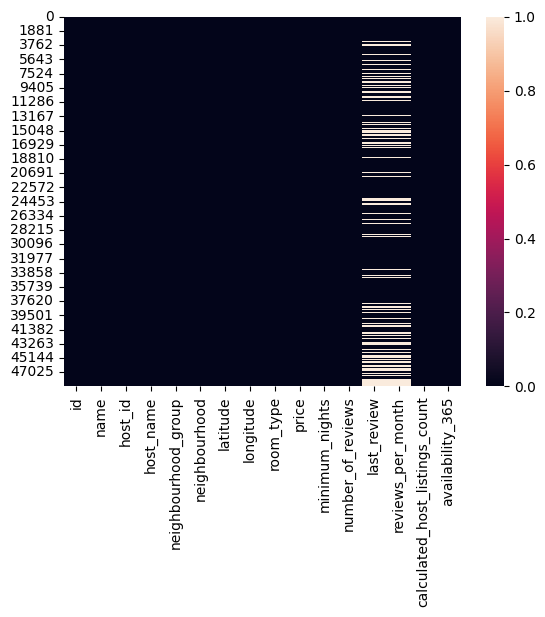

In [10]:
sns.heatmap(df.isnull())
plt.show()

In [11]:
df['reviews_per_month']=df['reviews_per_month'].fillna(0)
df['host_name']=df['host_name'].fillna('unknown')
df['host_id']=df['host_id'].fillna('unknown')

In [12]:
df.isnull().sum()

,0
id,0
name,16
host_id,0
host_name,0
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


In [13]:
df['price'].describe()

,price
count,48895.000000
mean,152.720687
std,240.154170
min,0.000000
25%,69.000000
50%,106.000000
75%,175.000000
max,10000.000000


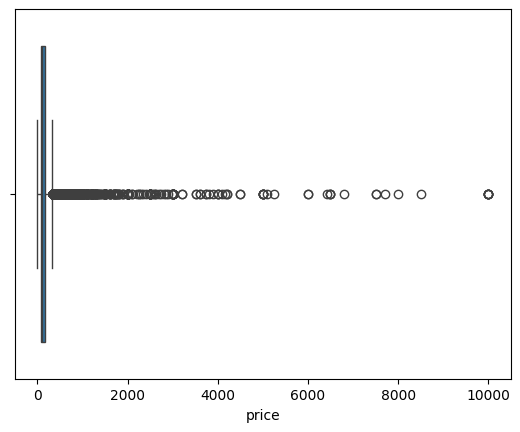

In [14]:
sns.boxplot(x=df['price'])
plt.show()

In [15]:
df['price'].median()

106.0

In [16]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1
lower= Q1 - 1.5*IQR
upper=Q3+1.5*IQR
print(lower,upper)

-90.0 334.0


In [17]:
(df['price']>upper).sum()

np.int64(2972)

In [18]:
df[df['price']>upper][['name','neighbourhood_group','room_type','price']].sort_values(by='price',ascending=False).head(10)

,name,neighbourhood_group,room_type,price
17692,Luxury 1 bedroom apt. -stunning Manhattan views,Brooklyn,Entire home/apt,10000
29238,1-BR Lincoln Center,Manhattan,Entire home/apt,10000
9151,Furnished room in Astoria apartment,Queens,Private room,10000
40433,2br - The Heart of NYC: Manhattans Lower East ...,Manhattan,Entire home/apt,9999
6530,Spanish Harlem Apt,Manhattan,Entire home/apt,9999
12342,"Quiet, Clean, Lit @ LES & Chinatown",Manhattan,Private room,9999
30268,Beautiful/Spacious 1 bed luxury flat-TriBeCa/Soho,Manhattan,Entire home/apt,8500
4377,Film Location,Brooklyn,Entire home/apt,8000
29662,East 72nd Townhouse by (Hidden by Airbnb),Manhattan,Entire home/apt,7703
42523,70' Luxury MotorYacht on the Hudson,Manhattan,Entire home/apt,7500


In [19]:
print("Mean:", df['price'].mean())
print("Median:", df['price'].median())
print("95th Percentile:", df['price'].quantile(0.95))
print("99th Percentile:", df['price'].quantile(0.99))

Mean: 152.7206871868289
Median: 106.0
95th Percentile: 355.0
99th Percentile: 799.0


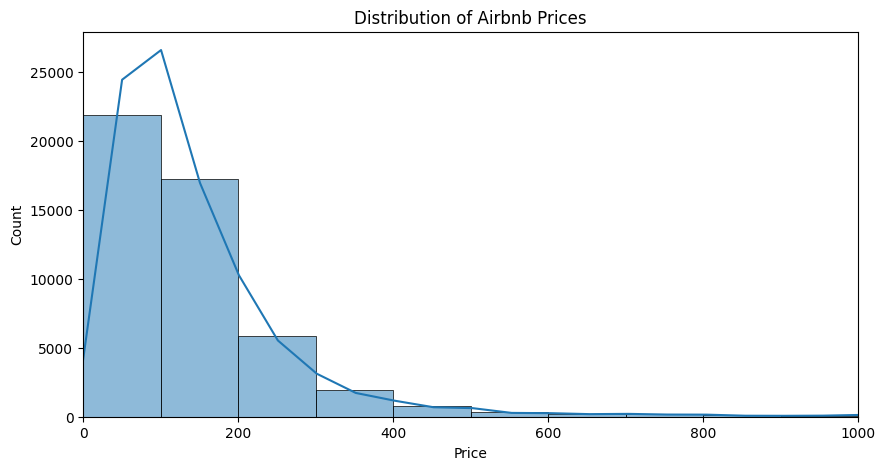

In [20]:
plt.figure(figsize=(10,5))
sns.histplot(df['price'],bins=100,kde=True)
plt.xlim(0,1000)
plt.title("Distribution of Airbnb Prices")
plt.xlabel("Price")
plt.show()

In [21]:
prices=np.array(df['price'])
price_conditions=[
    prices<100,
    prices<=300,
    prices<=700,
    prices>700
]
price_choices=['budget','moderate','expensive','luxury']
df['price_category']=np.select(price_conditions,price_choices,default='moderate')
df['price_category'].value_counts()

,count
price_category,
moderate,23661
budget,21877
expensive,2768
luxury,589


In [22]:
df['potential_revenue']=df['price']*df['minimum_nights']
df.sample(5)

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,price_category,potential_revenue
21843,17552185,Cozy Garden Apartment in Charming Park Slope,117035626,Anelcia Carolle,Brooklyn,Park Slope,40.67573,-73.97993,Entire home/apt,115,2,97,2019-07-03,3.68,1,0,moderate,230
27808,21803103,"Great Home & Host, next to #1 train",60163700,Dee,Manhattan,Harlem,40.82347,-73.95228,Private room,65,14,13,2019-05-19,0.69,4,0,budget,910
31165,24200751,2BR 3BD 1.5BA | Rooftop & Balcony | Airport Pi...,47424665,Brian,Queens,Ridgewood,40.70653,-73.90877,Entire home/apt,280,2,42,2019-06-23,3.44,2,108,moderate,560
34441,27312987,Bright and spacious room in Bushwick,89589630,Yaw,Brooklyn,Bushwick,40.69629,-73.91351,Private room,50,1,86,2019-06-30,7.70,1,198,budget,50
21271,16916191,Bedstuy Brownstone,61127125,Eric,Brooklyn,Bedford-Stuyvesant,40.68100,-73.94707,Entire home/apt,170,3,5,2019-06-23,0.50,1,66,moderate,510


In [23]:
reviews=np.array(df['number_of_reviews'])
review_conditions=[
    reviews==0,
    reviews<=10,
    reviews<=50,
    reviews>50
]
review_choices=['No reviews','low','moderate','high']
df['review_activity']=np.select(review_conditions,review_choices,default='unknown')
df['review_activity'].value_counts()

,count
review_activity,
low,20271
moderate,11613
No reviews,10052
high,6959


In [24]:
df['host_type']=np.where(
  (df['host_id'].map(df['host_id'].value_counts()) >1),
  'Multi-listing Host','Single Host')

df['host_type'].value_counts()

,count
host_type,
Single Host,32303
Multi-listing Host,16592


In [25]:
df[['price_category', 'potential_revenue', 'review_activity', 'host_type']].head()

,price_category,potential_revenue,review_activity,host_type
0,moderate,149,low,Multi-listing Host
1,moderate,225,moderate,Multi-listing Host
2,moderate,450,No reviews,Single Host
3,budget,89,high,Single Host
4,budget,800,low,Single Host


In [26]:
df['room_type'].value_counts()

,count
room_type,
Entire home/apt,25409
Private room,22326
Shared room,1160


In [27]:
df['room_type'].value_counts(normalize=True) * 100

,proportion
room_type,
Entire home/apt,51.966459
Private room,45.661111
Shared room,2.372431


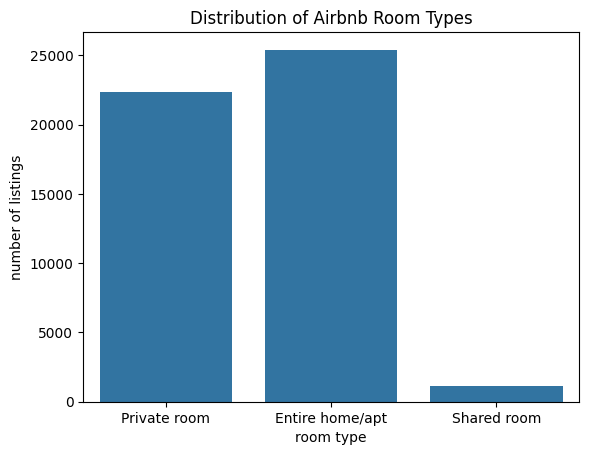

In [28]:
sns.countplot(data=df,x='room_type')
plt.title('Distribution of Airbnb Room Types')
plt.xlabel('room type')
plt.ylabel('number of listings')
plt.show()

In [29]:
df.groupby('neighbourhood_group')['price'].mean().sort_values(ascending=False)

,price
neighbourhood_group,
Manhattan,196.875814
Brooklyn,124.383207
Staten Island,114.812332
Queens,99.517649
Bronx,87.496792


In [30]:
df.groupby('neighbourhood_group')['price'].median().sort_values(ascending=False)

,price
neighbourhood_group,
Manhattan,150.0
Brooklyn,90.0
Queens,75.0
Staten Island,75.0
Bronx,65.0


In [31]:
df['neighbourhood_group'].value_counts()

,count
neighbourhood_group,
Manhattan,21661
Brooklyn,20104
Queens,5666
Bronx,1091
Staten Island,373


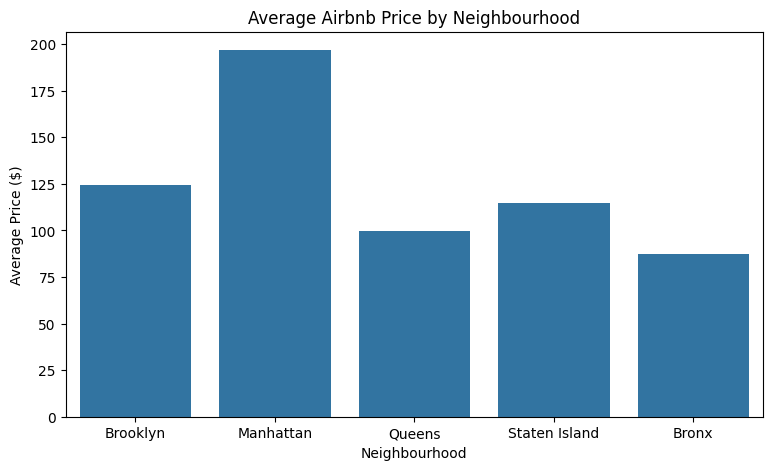

In [32]:
plt.figure(figsize=(9,5))

sns.barplot(
    data=df,
    x='neighbourhood_group',
    y='price',
    estimator='mean',
    errorbar=None
)

plt.title('Average Airbnb Price by Neighbourhood')
plt.xlabel('Neighbourhood')
plt.ylabel('Average Price ($)')
plt.show()

In [33]:
df['host_id'].value_counts().head(10)

,count
host_id,
219517861,327
107434423,232
30283594,121
137358866,103
16098958,96
12243051,96
61391963,91
22541573,87
200380610,65


In [34]:
top_hosts=df.groupby(['host_id','host_name']).size().sort_values(ascending=False).head(10)
top_hosts

,,0
host_id,host_name,
219517861,Sonder (NYC),327
107434423,Blueground,232
30283594,Kara,121
137358866,Kazuya,103
12243051,Sonder,96
16098958,Jeremy & Laura,96
61391963,Corporate Housing,91
22541573,Ken,87
200380610,Pranjal,65


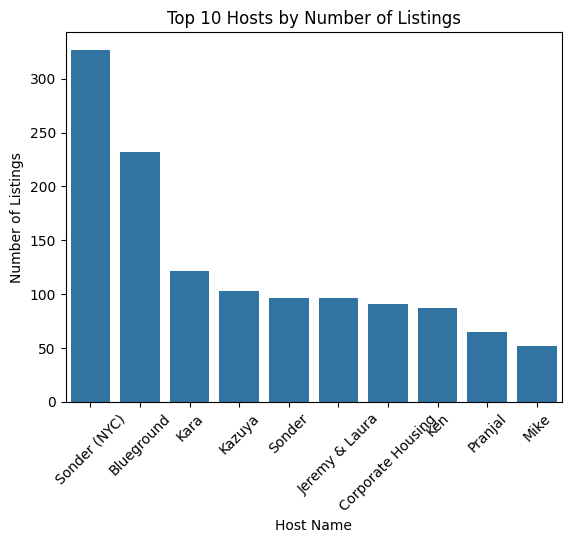

In [35]:
sns.barplot(

    x=top_hosts.index.get_level_values('host_name'),
    y=top_hosts.values,
    estimator='mean',
    errorbar=None
)
plt.title('Top 10 Hosts by Number of Listings')
plt.xlabel('Host Name')
plt.ylabel('Number of Listings')
plt.xticks(rotation=45)
plt.show()

In [36]:
df.groupby('room_type')['number_of_reviews'].mean().sort_values(ascending=False)

,number_of_reviews
room_type,
Private room,24.112962
Entire home/apt,22.842418
Shared room,16.600000


In [37]:
df.groupby('room_type')['number_of_reviews'].median().sort_values(ascending=False)

,number_of_reviews
room_type,
Entire home/apt,5.0
Private room,5.0
Shared room,4.0


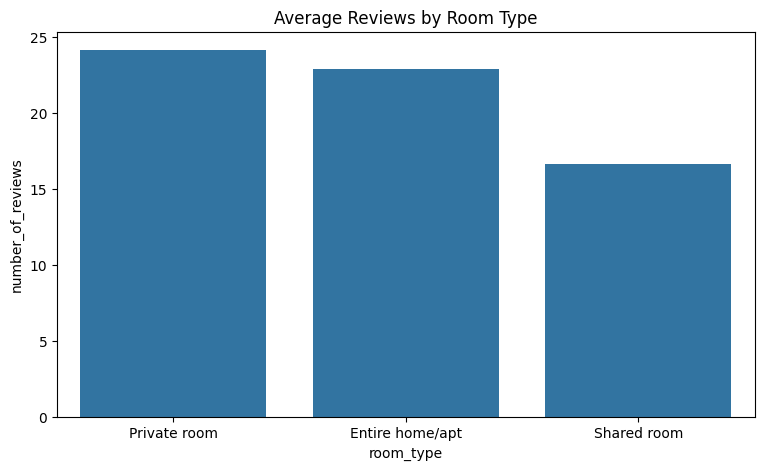

In [38]:
plt.figure(figsize=(9,5))

sns.barplot(
    data=df,
    x='room_type',
    y='number_of_reviews',
    errorbar=None,
)

plt.title('Average Reviews by Room Type')
plt.show()

In [39]:
df['room_type'].value_counts()

,count
room_type,
Entire home/apt,25409
Private room,22326
Shared room,1160


In [40]:
df.groupby('room_type')['availability_365'].mean().sort_values(ascending=False)

,availability_365
room_type,
Shared room,162.000862
Entire home/apt,111.920304
Private room,111.203933


In [41]:
df.groupby('room_type')['availability_365'].median().sort_values(ascending=False)

,availability_365
room_type,
Shared room,90.0
Private room,45.0
Entire home/apt,42.0


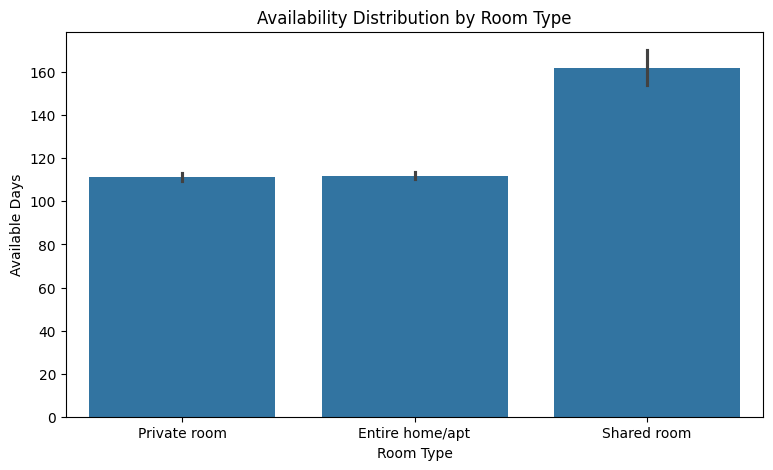

In [42]:
plt.figure(figsize=(9,5))

sns.barplot(data=df, x='room_type', y='availability_365')

plt.title('Availability Distribution by Room Type')
plt.xlabel('Room Type')
plt.ylabel('Available Days')
plt.show()

In [43]:
numerical_df=df.select_dtypes(include=np.number)
corr_matrix = numerical_df.corr()
corr_matrix

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,potential_revenue
id,1.000000,0.588290,-0.003125,0.090908,0.010619,-0.013224,-0.319760,0.180221,0.133272,0.085468,0.003796
host_id,0.588290,1.000000,0.020224,0.127055,0.015309,-0.017364,-0.140106,0.209783,0.154950,0.203492,0.002250
latitude,-0.003125,0.020224,1.000000,0.084788,0.033939,0.024869,-0.015389,-0.018758,0.019517,-0.010983,0.012169
longitude,0.090908,0.127055,0.084788,1.000000,-0.150019,-0.062747,0.059094,0.138516,-0.114713,0.082731,-0.039108
price,0.010619,0.015309,0.033939,-0.150019,1.000000,0.042799,-0.047954,-0.050564,0.057472,0.081829,0.444553
minimum_nights,-0.013224,-0.017364,0.024869,-0.062747,0.042799,1.000000,-0.080116,-0.124905,0.127960,0.144303,0.386293
number_of_reviews,-0.319760,-0.140106,-0.015389,0.059094,-0.047954,-0.080116,1.000000,0.589407,-0.072376,0.172028,-0.031563
reviews_per_month,0.180221,0.209783,-0.018758,0.138516,-0.050564,-0.124905,0.589407,1.000000,-0.047312,0.163732,-0.046166
calculated_host_listings_count,0.133272,0.154950,0.019517,-0.114713,0.057472,0.127960,-0.072376,-0.047312,1.000000,0.225701,0.054855
availability_365,0.085468,0.203492,-0.010983,0.082731,0.081829,0.144303,0.172028,0.163732,0.225701,1.000000,0.064083


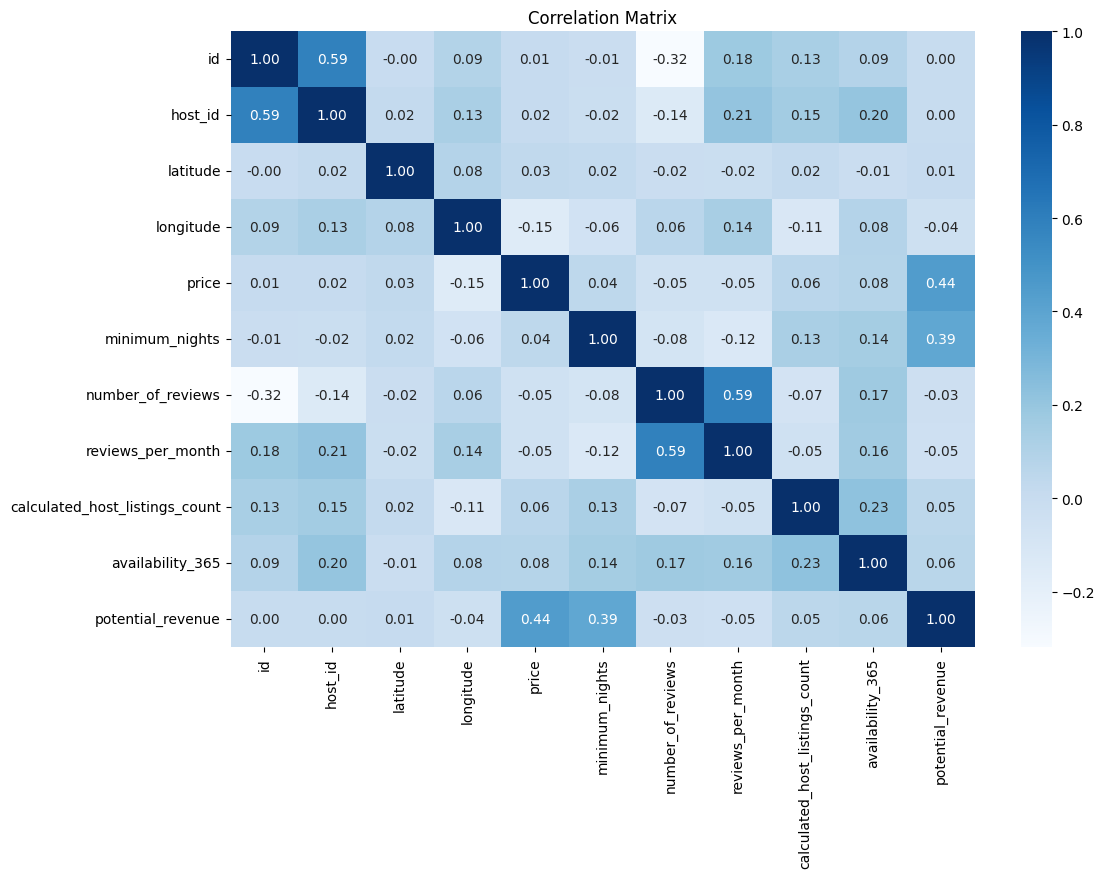

In [44]:
plt.figure(figsize=(12,8))

sns.heatmap(
    data=corr_matrix,
    annot=True,
    cmap='Blues',
    fmt='.2f'
)

plt.title('Correlation Matrix')
plt.show()

In [45]:
df.groupby('room_type')['price'].agg(['mean', 'median', 'std'])

,mean,median,std
room_type,,,
Entire home/apt,211.794246,160.0,284.041611
Private room,89.780973,70.0,160.205262
Shared room,70.127586,45.0,101.725252


In [46]:
df.groupby(['neighbourhood_group', 'room_type'])['price'].median().unstack()

room_type,Entire home/apt,Private room,Shared room
neighbourhood_group,,,
Bronx,100.0,53.5,40.0
Brooklyn,145.0,65.0,36.0
Manhattan,191.0,90.0,69.0
Queens,120.0,60.0,37.0
Staten Island,100.0,50.0,30.0


In [47]:
df.groupby('review_activity')['price'].agg(['mean', 'median', 'count'])

,mean,median,count
review_activity,,,
No reviews,192.919021,120.0,10052
high,128.707573,100.0,6959
low,148.819792,105.0,20271
moderate,139.124602,100.0,11613


In [48]:
df.groupby('review_activity')['availability_365'].agg(['mean', 'median'])

,mean,median
review_activity,,
No reviews,104.660466,6.0
high,164.266274,162.0
low,91.543880,5.0
moderate,126.029536,80.0


In [49]:
df.groupby('neighbourhood_group')['price_category'].value_counts(normalize=True).unstack() * 100

price_category,budget,expensive,luxury,moderate
neighbourhood_group,,,,
Bronx,75.435380,1.924840,0.274977,22.364803
Brooklyn,54.237963,3.198368,0.611819,41.951850
Manhattan,27.865750,9.283967,2.035917,60.814367
Queens,68.213908,1.570773,0.317684,29.897635
Staten Island,66.756032,1.072386,1.072386,31.099196


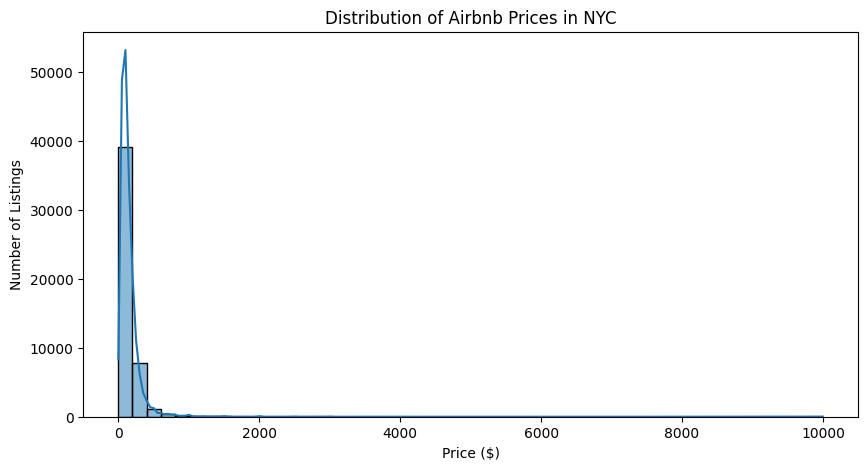

In [50]:
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x='price', bins=50, kde=True)

plt.title('Distribution of Airbnb Prices in NYC')
plt.xlabel('Price ($)')
plt.ylabel('Number of Listings')

plt.show()

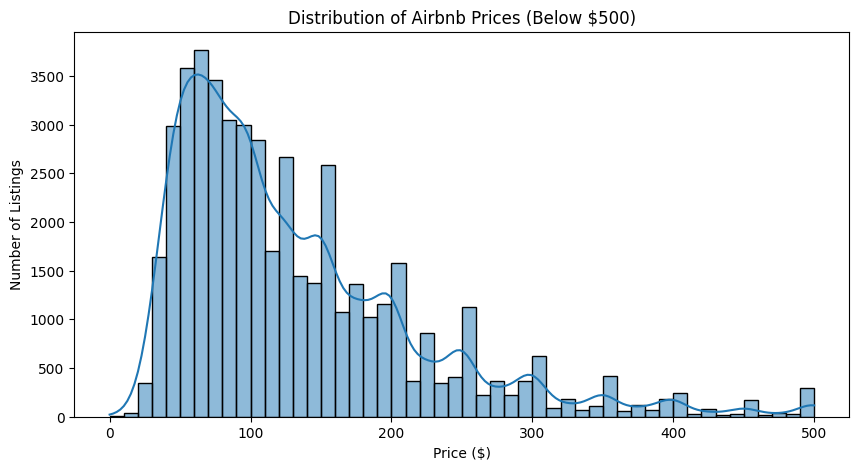

In [51]:
plt.figure(figsize=(10, 5))

sns.histplot(data=df[df['price'] <= 500], x='price', bins=50, kde=True)

plt.title('Distribution of Airbnb Prices (Below $500)')
plt.xlabel('Price ($)')
plt.ylabel('Number of Listings')

plt.show()

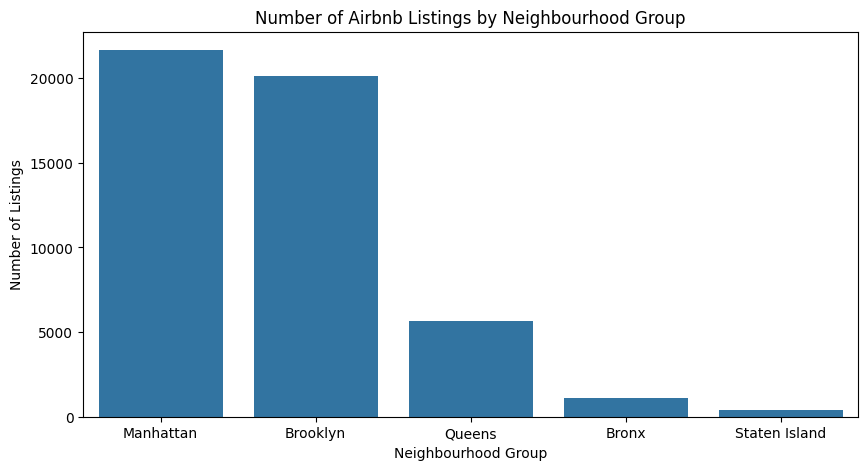

In [56]:
plt.figure(figsize=(10, 5))

sns.countplot(data=df, x='neighbourhood_group', order=df['neighbourhood_group'].value_counts().index)

plt.title('Number of Airbnb Listings by Neighbourhood Group')
plt.xlabel('Neighbourhood Group')
plt.ylabel('Number of Listings')

plt.show()

In [57]:
room_analysis = df.groupby(
    ['neighbourhood_group', 'room_type']
).agg(
    total_listings=('price', 'count'),
    average_price=('price', 'mean'),
    median_price=('price', 'median')
).round(2)

room_analysis

total_listings  average_price  \
neighbourhood_group room_type                                        
Bronx               Entire home/apt             379         127.51   
                    Private room                652          66.79   
                    Shared room                  60          59.80   
Brooklyn            Entire home/apt            9559         178.33   
                    Private room              10132          76.50   
                    Shared room                 413          50.53   
Manhattan           Entire home/apt           13199         249.24   
                    Private room               7982         116.78   
                    Shared room                 480          88.98   
Queens              Entire home/apt            2096         147.05   
                    Private room               3372          71.76   
                    Shared room                 198          69.02   
Staten Island       Entire home/apt             176         173.85   
                    Private room                188          62.29   
                    Shared room                   9          57.44   

                                     median_price  
neighbourhood_group room_type                      
Bronx               Entire home/apt         100.0  
                    Private room             53.5  
                    Shared room              40.0  
Brooklyn            Entire home/apt         145.0  
                    Private room             65.0  
                    Shared room              36.0  
Manhattan           Entire home/apt         191.0  
                    Private room             90.0  
                    Shared room              69.0  
Queens              Entire home/apt         120.0  
                    Private room             60.0  
                    Shared room              37.0  
Staten Island       Entire home/apt         100.0  
                    Private room             50.0  
                    Shared room              30.0

In [60]:
top_neighbourhoods = df.groupby('neighbourhood').agg(
    total_listings=('id', 'count'),
    average_price=('price', 'mean')
).sort_values(
    by='total_listings', ascending=False
).head(10).round(2)

top_neighbourhoods

,total_listings,average_price
neighbourhood,,
Williamsburg,3920,143.80
Bedford-Stuyvesant,3714,107.68
Harlem,2658,118.97
Bushwick,2465,84.80
Upper West Side,1971,210.92
Hell's Kitchen,1958,204.79
East Village,1853,186.08
Upper East Side,1798,188.95
Crown Heights,1564,112.48


In [61]:
top_hosts = df.groupby('host_id').agg(
    total_listings=('id', 'count'),
    host_name=('host_name', 'first')
).sort_values(
    by='total_listings', ascending=False
).head(10)

top_hosts

,total_listings,host_name
host_id,,
219517861,327,Sonder (NYC)
107434423,232,Blueground
30283594,121,Kara
137358866,103,Kazuya
12243051,96,Sonder
16098958,96,Jeremy & Laura
61391963,91,Corporate Housing
22541573,87,Ken
200380610,65,Pranjal


## Key Findings

1. **Geographical Distribution:** Manhattan and Brooklyn account for the majority of Airbnb listings in NYC, indicating a strong concentration of rental activity in these boroughs.

2. **Pricing Patterns:** Airbnb prices are highly right-skewed, with most listings concentrated in lower price ranges and a small number of expensive properties.

3. **Neighbourhood Differences:** Manhattan has the highest average prices across all three room types, while neighbourhoods such as Bushwick offer comparatively lower average prices.

4. **Room Type Analysis:** Entire homes and apartments generally have higher average prices than private and shared rooms across all five boroughs.

5. **Popular Neighbourhoods:** Williamsburg and Bedford-Stuyvesant have the highest listing counts among the neighbourhoods analysed.

6. **Host Activity:** Some hosts manage hundreds of listings, suggesting the presence of large-scale property operators in the Airbnb marketplace.

7. **Price Outliers:** The dataset contains extreme price values that significantly affect the overall price distribution. These were retained during cleaning rather than automatically removed.


Conclusion

This project involved an exploratory data analysis of the NYC Airbnb 2019 dataset to understand listing distributions, pricing patterns, room types, neighbourhood differences, and host activity.

Through data cleaning, feature engineering, statistical analysis, and visualization using Python libraries such as Pandas, NumPy, Matplotlib, and Seaborn, several meaningful patterns were identified.

The analysis revealed that Manhattan and Brooklyn dominate Airbnb listing activity, while Manhattan generally has higher accommodation prices. Entire homes and apartments are considerably more expensive than private and shared rooms. The analysis also highlighted popular neighbourhoods and hosts managing multiple properties.

Overall, this project provided practical experience in handling real-world datasets, identifying patterns, performing statistical analysis, and extracting meaningful insights using Python.

The findings offer a snapshot of the NYC Airbnb marketplace in 2019. Further analysis using booking data, customer reviews, and more recent datasets could provide deeper insights into market demand and pricing trends.